# Q1 - What is this dataset about? What is the scope?

Disclaimer : As the questions were in english, we decided to run this analysis in English;

Our goal here is to do a raw exploration of the data to get to know what we have inside.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / 'src'))  # not needed after `pip install -e .`

from ubi_churn.config import DataCatalog, load_params

catalog = DataCatalog.from_config()  # conf/base/catalog.yml
params = load_params()  # conf/base/parameters.yml

import matplotlib.pyplot as plt
import polars as pl

from ubi_churn.utils import exploration as ex

df_player_matches: pl.DataFrame = catalog.load('player_matches')  # typed match table (pipeline node `prepare`)
print(df_player_matches.shape)
df_player_matches.head()

(95733, 11)


playerid,matchid,gamemode,victory,kills,death,match_datetime,playernb_in_match,still_active,teammateid,opponentid
str,str,str,str,i64,i64,"datetime[μs, UTC]",i64,bool,str,str
"""00f2d75c-7aeb-465b-8d82-708583…","""7c5bf406-e736-4faf-9ad3-d0212e…","""PVP""","""FALSE""",0,3,2025-06-11 05:45:08.995 UTC,11,true,"""367d1918-35a1-44bc-ae39-889785…","""2fd83c37-e6bd-409a-8b43-5363c3…"
"""10c31731-4ea8-477b-bcf3-8b3424…","""006fd414-9d56-4c5c-bec4-1e177f…","""PVP""","""FALSE""",4,3,2025-09-24 13:23:27.592 UTC,10,false,"""52476f97-0543-4972-b0c4-a04f4e…","""3db5b6de-7df1-437b-86f2-6d8792…"
"""10c31731-4ea8-477b-bcf3-8b3424…","""0199977b-f28e-4518-a20b-6b3bbb…","""PVP""","""TRUE""",6,4,2025-09-24 13:36:40.815 UTC,11,false,"""425463e6-cb7f-4228-8ae8-208955…","""2a328963-a705-46bc-8111-df7f9a…"
"""10c31731-4ea8-477b-bcf3-8b3424…","""025350fc-7001-48c8-b359-eb208b…","""PVP_UNRANKED""","""TRUE""",7,7,2025-10-13 08:44:06.557 UTC,10,false,"""0b8c311b-078f-40cc-b27a-f212ee…","""30956267-5e4e-4900-b328-e6a68b…"
"""10c31731-4ea8-477b-bcf3-8b3424…","""0257807d-b22e-461d-ac17-4cc23b…","""PVP_UNRANKED""","""FALSE""",4,4,2025-10-29 18:44:53.168 UTC,10,false,"""17a6aa85-511c-4938-890d-d2bb62…","""2a894c13-b51d-4a0c-9e65-748583…"


## 1. Columns summary

Observation : 
- We can see 95k rows
- we may expect null value in kills and death
- We are surprise to see category "other" in the column Victory and a gamemode "Operations"


In [2]:
df_player_matches.describe()

statistic,playerid,matchid,gamemode,victory,kills,death,match_datetime,playernb_in_match,still_active,teammateid,opponentid
str,str,str,str,str,f64,f64,str,f64,f64,str,str
"""count""","""95733""","""95733""","""95733""","""95733""",95580.0,95580.0,"""95733""",95733.0,95733.0,"""95727""","""95722"""
"""null_count""","""0""","""0""","""0""","""0""",153.0,153.0,"""0""",0.0,0.0,"""6""","""11"""
"""mean""",null,null,null,null,3.530163,3.587278,"""2025-08-16 05:48:19.204814+00:…",10.490886,0.754714,null,null
"""std""",null,null,null,null,2.793863,1.806768,null,1.291366,null,null,null
"""min""","""00229b3f-4e74-4e8d-b6ce-37df9a…","""000086b5-2ee3-4077-802d-a9d3c2…","""OPERATIONS""","""FALSE""",0.0,0.0,"""2025-03-04 15:04:17.034000+00:…",1.0,0.0,"""00001f5e-5da5-4526-8e0e-65f65d…","""000010d9-8206-4a76-a4b3-ce23d9…"
"""25%""",null,null,null,null,1.0,2.0,"""2025-05-25 11:14:57.090000+00:…",10.0,null,null,null
"""50%""",null,null,null,null,3.0,4.0,"""2025-07-31 19:58:16.679000+00:…",10.0,null,null,null
"""75%""",null,null,null,null,5.0,5.0,"""2025-11-12 11:11:00.576000+00:…",10.0,null,null,null
"""max""","""ffd631ed-b4b9-496b-a25b-848adb…","""fffd982f-5673-48ad-90db-c1f923…","""PVP_UNRANKED""","""other""",26.0,9.0,"""2026-03-03 13:54:20.190000+00:…",25.0,1.0,"""f39bc86b-096b-4405-9339-dac535…","""e897013f-51b6-44ed-b1a3-87d682…"


## 2. Number of player concerned

Do we have multiple rows per match id? What is the period concerned and players to analyse.

In [3]:
row_count: int = df_player_matches.height
ex.print_dict(ex.dataset_scope(df_player_matches))

rows                       : 95733
duplicated (player, match) : 0
distinct players           : 840
distinct matches           : 95722
first match                : 2025-03-04 15:04:17.034000+00:00
last match                 : 2026-03-03 13:54:20.190000+00:00
span (days)                : 363
unparseable dates          : 0


## 3. Categorical columns

`victory` supposed to be a bool holds `draw` and `other`.
`PVP` stands for player vs player, we were expecting to have a bool - either Ranked or Unranked but we see PVP and OPERATIONS.

hypothesis : PVP is a fallback for player without account or player creating their own party (fun - training)


still_active seems to be the column to be used in a classification exercise (Churn) we see that it is imbalanced and Binary - at least on row level.

In [4]:
for column_name in ['victory', 'gamemode', 'still_active']:
    print(ex.share_by_category(df_player_matches, column_name, decimals=2))

shape: (4, 3)
┌─────────┬───────────┬───────────┐
│ victory ┆ row_count ┆ share_pct │
│ ---     ┆ ---       ┆ ---       │
│ str     ┆ u32       ┆ f64       │
╞═════════╪═══════════╪═══════════╡
│ FALSE   ┆ 49760     ┆ 51.98     │
│ TRUE    ┆ 45917     ┆ 47.96     │
│ draw    ┆ 43        ┆ 0.04      │
│ other   ┆ 13        ┆ 0.01      │
└─────────┴───────────┴───────────┘
shape: (4, 3)
┌──────────────┬───────────┬───────────┐
│ gamemode     ┆ row_count ┆ share_pct │
│ ---          ┆ ---       ┆ ---       │
│ str          ┆ u32       ┆ f64       │
╞══════════════╪═══════════╪═══════════╡
│ PVP_RANKED   ┆ 48563     ┆ 50.73     │
│ PVP          ┆ 32267     ┆ 33.71     │
│ PVP_UNRANKED ┆ 14898     ┆ 15.56     │
│ OPERATIONS   ┆ 5         ┆ 0.01      │
└──────────────┴───────────┴───────────┘
shape: (2, 3)
┌──────────────┬───────────┬───────────┐
│ still_active ┆ row_count ┆ share_pct │
│ ---          ┆ ---       ┆ ---       │
│ bool         ┆ u32       ┆ f64       │
╞══════════════╪════════

## 4. Matches per game mode, with detail per victory

Let's check the cross impact of 'draw' and 'other'


shape: (4, 4)
┌──────────────┬─────────────┬───────────┬───────────┐
│ gamemode     ┆ match_count ┆ row_count ┆ share_pct │
│ ---          ┆ ---         ┆ ---       ┆ ---       │
│ str          ┆ u32         ┆ u32       ┆ f64       │
╞══════════════╪═════════════╪═══════════╪═══════════╡
│ PVP_RANKED   ┆ 48557       ┆ 48563     ┆ 50.73     │
│ PVP          ┆ 32263       ┆ 32267     ┆ 33.7      │
│ PVP_UNRANKED ┆ 14897       ┆ 14898     ┆ 15.56     │
│ OPERATIONS   ┆ 5           ┆ 5         ┆ 0.01      │
└──────────────┴─────────────┴───────────┴───────────┘


shape: (4, 5)
┌──────────────┬───────┬───────┬──────┬───────┐
│ gamemode     ┆ TRUE  ┆ FALSE ┆ draw ┆ other │
│ ---          ┆ ---   ┆ ---   ┆ ---  ┆ ---   │
│ str          ┆ u32   ┆ u32   ┆ u32  ┆ u32   │
╞══════════════╪═══════╪═══════╪══════╪═══════╡
│ OPERATIONS   ┆ 1     ┆ 2     ┆ 0    ┆ 2     │
│ PVP          ┆ 13970 ┆ 18283 ┆ 8    ┆ 6     │
│ PVP_RANKED   ┆ 24336 ┆ 24196 ┆ 27   ┆ 4     │
│ PVP_UNRANKED ┆ 7610  ┆ 7279  ┆ 8    ┆ 1     │
└──────────────┴───────┴───────┴──────┴───────┘
shape: (15, 4)
┌──────────────┬─────────┬───────────┬───────────────────────┐
│ gamemode     ┆ victory ┆ row_count ┆ share_in_gamemode_pct │
│ ---          ┆ ---     ┆ ---       ┆ ---                   │
│ str          ┆ str     ┆ u32       ┆ f64                   │
╞══════════════╪═════════╪═══════════╪═══════════════════════╡
│ OPERATIONS   ┆ FALSE   ┆ 2         ┆ 40.0                  │
│ OPERATIONS   ┆ TRUE    ┆ 1         ┆ 20.0                  │
│ OPERATIONS   ┆ other   ┆ 2         ┆ 40.0       

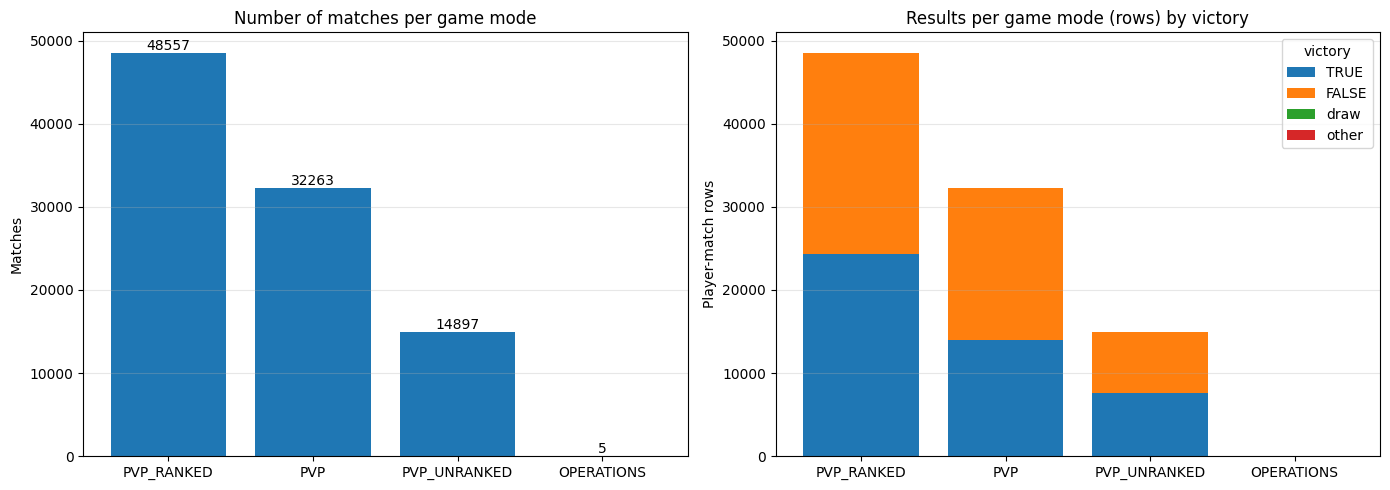

In [5]:
VICTORY_ORDER: list[str] = params['exploration']['victory_order']

df_matches_per_gamemode: pl.DataFrame = ex.matches_per_gamemode(df_player_matches)
print(df_matches_per_gamemode)
gamemode_order: list[str] = df_matches_per_gamemode['gamemode'].to_list()

df_victory_per_gamemode: pl.DataFrame = ex.victory_per_gamemode(df_player_matches)
print(
    df_victory_per_gamemode
    .pivot(on='victory', index='gamemode', values='row_count')
    .fill_null(0)
    .select('gamemode', *[c for c in VICTORY_ORDER if c in df_victory_per_gamemode['victory'].to_list()])
    .sort('gamemode')
)
print(df_victory_per_gamemode.sort('gamemode', 'victory'))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# left: matches per game mode
bars = axes[0].bar(gamemode_order, df_matches_per_gamemode['match_count'])
axes[0].bar_label(bars)
axes[0].set_title('Number of matches per game mode')
axes[0].set_ylabel('Matches')
axes[0].grid(axis='y', alpha=0.3)

# right: victory split per game mode, stacked
bottom: list[float] = [0.0] * len(gamemode_order)
for victory_value in VICTORY_ORDER:
    counts: list[int] = [
        df_victory_per_gamemode.filter((pl.col('gamemode') == gamemode) & (pl.col('victory') == victory_value))['row_count'].sum()
        for gamemode in gamemode_order
    ]
    axes[1].bar(gamemode_order, counts, bottom=bottom, label=victory_value)
    bottom = [b + c for b, c in zip(bottom, counts)]
axes[1].set_title('Results per game mode (rows) by victory')
axes[1].set_ylabel('Player-match rows')
axes[1].legend(title='victory')
axes[1].grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

## 5. Number of games per day

can we see a seasonnality? - We expect more party during holidays

we can observe peak not on EOY period but on April and June

- is it due to promotion? streamer? Ads trend? Launch of the game? Remake? DLC?

shape: (9, 2)
┌────────────┬────────────┐
│ statistic  ┆ value      │
│ ---        ┆ ---        │
│ str        ┆ f64        │
╞════════════╪════════════╡
│ count      ┆ 364.0      │
│ null_count ┆ 0.0        │
│ mean       ┆ 262.972527 │
│ std        ┆ 92.189673  │
│ min        ┆ 92.0       │
│ 25%        ┆ 194.0      │
│ 50%        ┆ 253.0      │
│ 75%        ┆ 323.0      │
│ max        ┆ 632.0      │
└────────────┴────────────┘


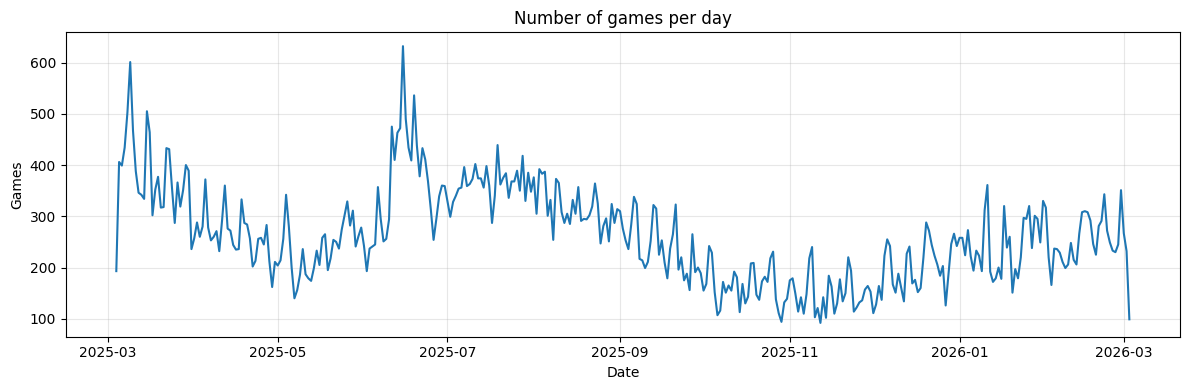

In [6]:
df_games_per_day: pl.DataFrame = ex.build_games_per_day(df_player_matches)
print(df_games_per_day['game_count'].describe())

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df_games_per_day['match_date'], df_games_per_day['game_count'])
ax.set_title('Number of games per day')
ax.set_xlabel('Date')
ax.set_ylabel('Games')
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 6. Distributions: kills, deaths, players per match

Looks like it is mostly a 10 players game (To check, 5v5 game?)

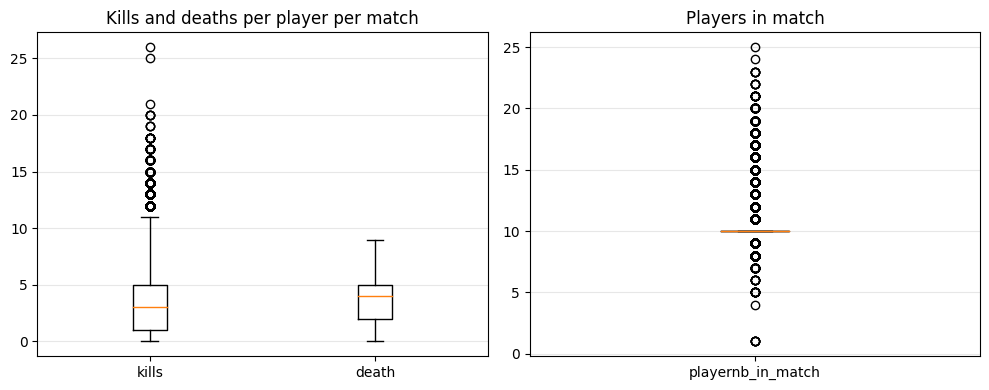

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].boxplot([df_player_matches['kills'].drop_nulls(), df_player_matches['death'].drop_nulls()])
axes[0].set_xticklabels(['kills', 'death'])
axes[0].set_title('Kills and deaths per player per match')
axes[0].grid(axis='y', alpha=0.3)

axes[1].boxplot(df_player_matches['playernb_in_match'].drop_nulls())
axes[1].set_xticklabels(['playernb_in_match'])
axes[1].set_title('Players in match')
axes[1].grid(axis='y', alpha=0.3)

fig.tight_layout()
plt.show()

In [8]:
df_player_matches.select('kills', 'death', 'playernb_in_match').describe(percentiles=[0.25, 0.5, 0.75, 0.99])

statistic,kills,death,playernb_in_match
str,f64,f64,f64
"""count""",95580.0,95580.0,95733.0
"""null_count""",153.0,153.0,0.0
"""mean""",3.530163,3.587278,10.490886
"""std""",2.793863,1.806768,1.291366
"""min""",0.0,0.0,1.0
"""25%""",1.0,2.0,10.0
"""50%""",3.0,4.0,10.0
"""75%""",5.0,5.0,10.0
"""99%""",12.0,8.0,16.0


## Conclusion

- We seem to have 100k match for around 900 player
- 10 players per party
- Around one year of data
- Null value to be cautious with